# Does the steerability screen predict distillation transfer across receivers?

**Question.** The steerability screen injects a teacher-derived steering vector into a *base*
receiver model and measures how much animal preference it can induce. If that screen is a
usable cheap proxy, then (a) receivers that steer better should distil better, and (b) within a
receiver, teachers whose vectors steer better should distil better. This notebook tests both.

**Design.**
- **Teachers:** the 10 `param_tags` of `run_logs/dog_top10_kband_configs.json` — dog, finetuned on
  the *original* pythia-160m, teacher ftseed 1.
- **Receivers:** `orig` (pythia-160m), `ds1` (pythia-160m-data-seed1), `fs1` (pythia-160m-seed1).
- **Screen:** `teachers/dog/pythia-160m/{tag}/steerability/{self|steer_data-seed1|steer_full-seed1}/aggregate.json`.
  Peak over the (layer x alpha) grid is **selected on the `favorite` prompt set** and **reported on
  the held-out `validation` set** (screen `selection_set` field), seed 1 only.
- **Transfer:** student cells at
  `students/dog/{receiver}/teacher-pythia-160m/{tag}_tseed1/ex10-20_prefix_n100k/{cell}/ftseed*/`,
  score = `sets.test.p_target`. Restricted to the **56 student cells present for all 10 teachers x
  all 3 receivers** (computed intersection, asserted). Aggregation is **per cell first** (mean over
  ftseeds inside a cell — ds1 has extra seeds on a few cells, which must not double-count), then
  mean/median over the 56 cells.
- **Prior reference:** `transfer_factors.load_priors` `test_prior` — the base model's mean exact
  p(dog) on the same 50 held-out `test` prompts, taken **per receiver base** (like-for-like).

Date: 2026-09-12.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

from subliminal_learning.config import load_paths_local

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

OUT = Path(load_paths_local()["output_root"])
TAGS = json.loads(Path("../run_logs/dog_top10_kband_configs.json").read_text())["param_tags"]

# receiver label -> (students base dir, steerability subdir, base_label used by load_priors)
RECV = {
    "orig": ("pythia-160m", "self", "original"),
    "ds1": ("pythia-160m-data-seed1", "steer_data-seed1", "data-seed1"),
    "fs1": ("pythia-160m-seed1", "steer_full-seed1", "full-seed1"),
}
POOL = "ex10-20_prefix_n100k"
print(OUT, len(TAGS), "teachers")

/mnt/cold-1/soar-subliminal/angela/outputs 10 teachers


In [2]:
def screen_row(tag: str, subdir: str) -> dict:
    """One steerability-screen aggregate: peak-over-grid, selected on favorite, reported on validation."""
    d = json.loads((OUT / "teachers/dog/pythia-160m" / tag / "steerability" / subdir / "aggregate.json").read_text())
    pk = d["peaks"]
    return {
        "ungated_delta": pk["ungated"]["delta_val_p_mean"],
        "recovery": pk["ungated"]["recovery_frac_mean"],
        "gated_off_delta": pk["gated_off"]["delta_val_p_mean"],
        "gated_off_n": pk["gated_off"]["gated_n"],
        "gated_neg_off_delta": pk["gated_neg_off"]["delta_val_p_mean"],
        "gated_neg_off_n": pk["gated_neg_off"]["gated_n"],
        "teacher_val_p": d["teacher_val_p_mean"],
        "base_val_p": d["base_val_p"],
        "selection_set": d["selection_set"],
    }


def cell_scores(tag: str, base_dir: str) -> dict[str, float]:
    """cell -> mean test p_target over that cell's ftseeds (per-cell-first aggregation)."""
    root = OUT / "students/dog" / base_dir / "teacher-pythia-160m" / f"{tag}_tseed1" / POOL
    out = {}
    if not root.exists():
        return out
    for cell in sorted(root.iterdir()):
        if not cell.is_dir() or cell.name == "eas":
            continue
        vals = []
        for seed in sorted(cell.glob("ftseed*")):
            f = seed / "eval" / "preference_eval.json"
            if not f.exists():
                f = seed / "preference_eval.json"
            if f.exists():
                vals.append(float(json.loads(f.read_text())["sets"]["test"]["p_target"]))
        if vals:
            out[cell.name] = float(np.mean(vals))
    return out


CELLS = {(r, t): cell_scores(t, b) for r, (b, _s, _p) in RECV.items() for t in TAGS}
SHARED = sorted(set.intersection(*(set(v) for v in CELLS.values())))
assert len(SHARED) == 56, len(SHARED)
print(f"{len(SHARED)} shared cells across 10 teachers x 3 receivers")

56 shared cells across 10 teachers x 3 receivers


In [3]:
from subliminal_learning.analysis.transfer_factors import load_priors

_pri = load_priors(OUT)
_pri = _pri[_pri["animal"] == "dog"].set_index("base_label")["test_prior"]
PRIOR = {r: float(_pri[p]) for r, (_b, _s, p) in RECV.items()}
PRIOR

{'orig': 0.009626890126382933,
 'ds1': 0.01331639617215842,
 'fs1': 0.008173296888999175}

In [4]:
rows = []
for r, (_b, sub, _p) in RECV.items():
    for t in TAGS:
        v = np.array([CELLS[(r, t)][c] for c in SHARED])
        rows.append({"receiver": r, "teacher": t,
                     "transfer_mean": v.mean(), "transfer_median": float(np.median(v)),
                     "transfer_mean_x_prior": v.mean() / PRIOR[r],
                     "n_cells": len(v), **screen_row(t, sub)})
df = pd.DataFrame(rows)

print("Row unit: one (receiver, teacher) pair. 3 receivers x 10 teachers = 30 rows.")
print("transfer_mean/median: mean/median over the 56 SHARED student cells of the per-cell mean")
print("  test p(dog) (mean over that cell's ftseeds first). transfer_mean_x_prior divides by that")
print("  receiver base's own dog test prior (load_priors test_prior).")
print("Screen columns: peak over the (layer x alpha) grid selected on the `favorite` set and")
print("  reported on `validation`; deltas are val_p minus base_val_p. gated_* peaks are restricted")
print("  to grid points passing the off-topic (and dislike) leakage gates; *_n = how many passed.")
df.round(4)

Row unit: one (receiver, teacher) pair. 3 receivers x 10 teachers = 30 rows.
transfer_mean/median: mean/median over the 56 SHARED student cells of the per-cell mean
  test p(dog) (mean over that cell's ftseeds first). transfer_mean_x_prior divides by that
  receiver base's own dog test prior (load_priors test_prior).
Screen columns: peak over the (layer x alpha) grid selected on the `favorite` set and
  reported on `validation`; deltas are val_p minus base_val_p. gated_* peaks are restricted
  to grid points passing the off-topic (and dislike) leakage gates; *_n = how many passed.


,receiver,teacher,transfer_mean,transfer_median,transfer_mean_x_prior,n_cells,ungated_delta,recovery,gated_off_delta,gated_off_n,gated_neg_off_delta,gated_neg_off_n,teacher_val_p,base_val_p,selection_set
0,orig,ep20_lr1e-4_r16a32,0.7078,0.7537,73.5249,56,0.9903,1.0000,0.8894,1,0.0888,1,1.0000,0.0097,favorite
1,orig,ep2_lr5e-4_r32a64,0.6080,0.5912,63.1606,56,0.9862,0.9961,0.9008,1,0.1026,1,0.9998,0.0097,favorite
2,orig,ep7_lr5e-4_r8a8,0.7003,0.7315,72.7483,56,0.9888,0.9986,0.9811,1,0.0888,1,0.9999,0.0097,favorite
3,orig,ep10_lr1e-4_r64a64,0.6373,0.6536,66.1952,56,0.9903,1.0000,0.8839,1,0.0958,1,1.0000,0.0097,favorite
4,orig,ep20_lr1e-4_r8a16,0.5397,0.5492,56.0614,56,0.9881,0.9978,0.9198,1,0.0778,1,0.9999,0.0097,favorite
5,orig,ep5_lr5e-4_r8a16,0.5829,0.6127,60.5498,56,0.9846,0.9947,0.9748,1,0.0814,1,0.9996,0.0097,favorite
6,orig,ep5_lr2e-4_r64a64,0.6193,0.6710,64.3267,56,0.9855,0.9953,0.9330,1,0.0919,1,0.9999,0.0097,favorite
7,orig,ep7_lr2e-4_r32a32,0.5600,0.6095,58.1739,56,0.9897,0.9995,0.9582,1,0.0709,1,1.0000,0.0097,favorite
8,orig,ep10_lr1e-4_r32a64,0.5877,0.6276,61.0490,56,0.9902,1.0000,0.9208,1,0.0902,1,1.0000,0.0097,favorite
9,orig,ep7_lr1e-4_r32a64,0.5099,0.5160,52.9615,56,0.9882,0.9981,0.9398,1,0.0937,1,0.9999,0.0097,favorite


In [5]:
SCREEN = ["ungated_delta", "gated_off_delta", "gated_neg_off_delta", "recovery"]
out = []
for r in list(RECV) + ["POOLED"]:
    d = df if r == "POOLED" else df[df["receiver"] == r]
    row = {"group": r, "n": len(d)}
    for m in SCREEN:
        row[f"{m}|spearman"] = spearmanr(d["transfer_mean"], d[m]).statistic
        row[f"{m}|pearson"] = pearsonr(d["transfer_mean"], d[m]).statistic
    out.append(row)
corr = pd.DataFrame(out).set_index("group")

print("Row unit: one receiver (n=10 teachers each) plus the POOLED 30-row fit.")
print("Columns: Spearman / Pearson correlation of transfer_mean against each screen metric.")
print("Selection: the 10 top-10 kband dog teachers; transfer over the 56 shared cells.")
print("IMPORTANT: the POOLED row is dominated by the RECEIVER level, not by teacher ranking --")
print("  both transfer and screen delta fall orig >> ds1 >> fs1, so any pooled correlation mostly")
print("  re-expresses that 3-point between-receiver ordering. The three within-receiver rows are")
print("  the informative test of whether the screen RANKS TEACHERS.")
corr.round(3)

Row unit: one receiver (n=10 teachers each) plus the POOLED 30-row fit.
Columns: Spearman / Pearson correlation of transfer_mean against each screen metric.
Selection: the 10 top-10 kband dog teachers; transfer over the 56 shared cells.
IMPORTANT: the POOLED row is dominated by the RECEIVER level, not by teacher ranking --
  both transfer and screen delta fall orig >> ds1 >> fs1, so any pooled correlation mostly
  re-expresses that 3-point between-receiver ordering. The three within-receiver rows are
  the informative test of whether the screen RANKS TEACHERS.


,n,ungated_delta|spearman,ungated_delta|pearson,gated_off_delta|spearman,gated_off_delta|pearson,gated_neg_off_delta|spearman,gated_neg_off_delta|pearson,recovery|spearman,recovery|pearson
group,,,,,,,,,
orig,10,0.406,0.223,-0.297,-0.164,0.261,0.285,0.406,0.223
ds1,10,0.442,0.598,0.442,0.598,0.079,-0.444,0.442,0.598
fs1,10,-0.079,-0.243,-0.079,-0.243,-0.079,-0.243,-0.079,-0.243
POOLED,30,0.918,0.868,0.892,0.847,0.690,0.536,0.918,0.868


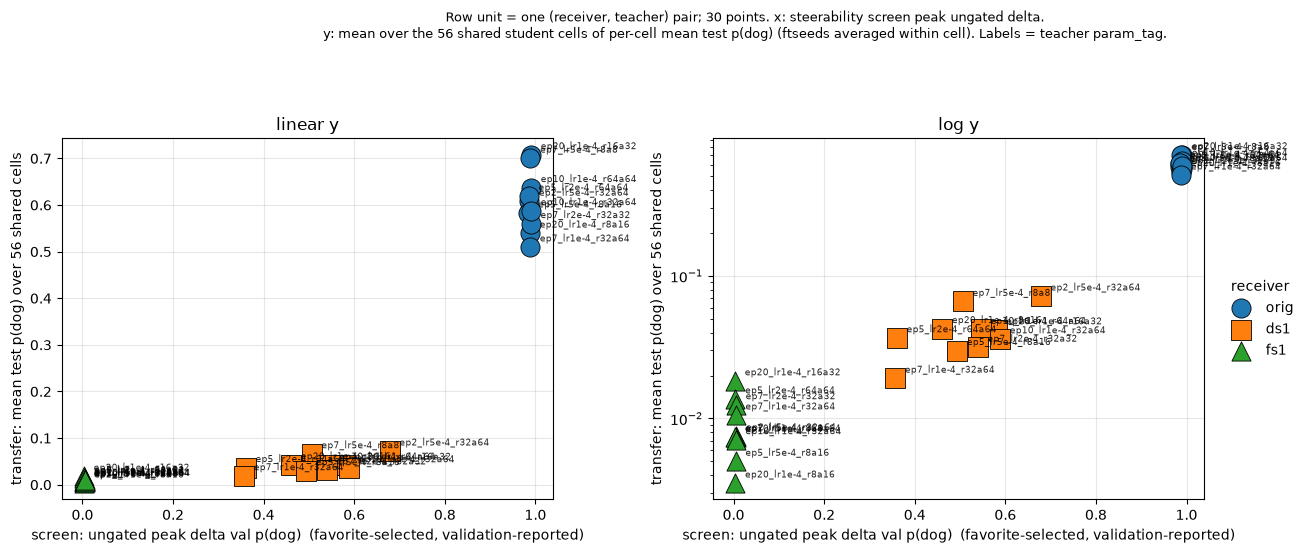

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
marks = {"orig": "o", "ds1": "s", "fs1": "^"}
cols = {"orig": "tab:blue", "ds1": "tab:orange", "fs1": "tab:green"}
for ax, logy in zip(axes, [False, True]):
    for r in RECV:
        d = df[df["receiver"] == r]
        ax.scatter(d["ungated_delta"], d["transfer_mean"], s=190, marker=marks[r],
                   color=cols[r], edgecolor="black", linewidth=0.6, label=r, zorder=3)
        for _, row in d.iterrows():
            ax.annotate(row["teacher"], (row["ungated_delta"], row["transfer_mean"]),
                        textcoords="offset points", xytext=(7, 4), fontsize=6.5, alpha=0.85)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("screen: ungated peak delta val p(dog)  (favorite-selected, validation-reported)")
    ax.set_ylabel("transfer: mean test p(dog) over 56 shared cells")
    ax.set_title("log y" if logy else "linear y")
    ax.grid(alpha=0.3)
axes[1].legend(title="receiver", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
               markerscale=1.0)
fig.suptitle("Row unit = one (receiver, teacher) pair; 30 points. x: steerability screen peak "
             "ungated delta.\ny: mean over the 56 shared student cells of per-cell mean test "
             "p(dog) (ftseeds averaged within cell). Labels = teacher param_tag.", fontsize=9)
fig.tight_layout(rect=(0, 0, 0.88, 0.9))
plt.show()

In [7]:
summ = (df.groupby("receiver")
          .agg(mean_transfer=("transfer_mean", "mean"),
               mean_transfer_x_prior=("transfer_mean_x_prior", "mean"),
               mean_ungated_delta=("ungated_delta", "mean"),
               mean_gated_off_delta=("gated_off_delta", "mean"),
               mean_base_val_p=("base_val_p", "mean"),
               test_prior=("receiver", lambda s: PRIOR[s.iloc[0]]))
          .loc[list(RECV)])

print("Row unit: one receiver (aggregate over its 10 teachers). 3 rows.")
print("mean_transfer: mean over 10 teachers of the teacher's mean over 56 shared cells.")
print("mean_transfer_x_prior: same, in multiples of that receiver base's dog test prior.")
print("mean_ungated_delta / mean_gated_off_delta: mean over teachers of the screen peak delta.")
print("mean_base_val_p: the receiver base's unsteered validation p(dog) (constant per receiver).")
summ.round(4)

Row unit: one receiver (aggregate over its 10 teachers). 3 rows.
mean_transfer: mean over 10 teachers of the teacher's mean over 56 shared cells.
mean_transfer_x_prior: same, in multiples of that receiver base's dog test prior.
mean_ungated_delta / mean_gated_off_delta: mean over teachers of the screen peak delta.
mean_base_val_p: the receiver base's unsteered validation p(dog) (constant per receiver).


,mean_transfer,mean_transfer_x_prior,mean_ungated_delta,mean_gated_off_delta,mean_base_val_p,test_prior
receiver,,,,,,
orig,0.6053,62.8751,0.9882,0.9302,0.0097,0.0096
ds1,0.0419,3.1428,0.5110,0.5110,0.0128,0.0133
fs1,0.0093,1.1385,0.0044,0.0044,0.0104,0.0082


In [8]:
print("Teacher validation p(dog) per teacher (screen `teacher_val_p_mean`) -- saturation check:")
print(df.groupby("teacher")["teacher_val_p"].mean().round(6).to_string())
print()
print("gated_off / gated_neg_off surviving grid points per receiver (gated_n):")
print(df.groupby("receiver")[["gated_off_n", "gated_neg_off_n"]].describe().round(2).to_string())

Teacher validation p(dog) per teacher (screen `teacher_val_p_mean`) -- saturation check:
teacher
ep10_lr1e-4_r32a64    0.999990
ep10_lr1e-4_r64a64    0.999984
ep20_lr1e-4_r16a32    0.999997
ep20_lr1e-4_r8a16     0.999921
ep2_lr5e-4_r32a64     0.999825
ep5_lr2e-4_r64a64     0.999948
ep5_lr5e-4_r8a16      0.999562
ep7_lr1e-4_r32a64     0.999894
ep7_lr2e-4_r32a32     0.999954
ep7_lr5e-4_r8a8       0.999865

gated_off / gated_neg_off surviving grid points per receiver (gated_n):
         gated_off_n                                    gated_neg_off_n                                   
               count mean  std  min  25%  50%  75%  max           count mean  std  min  25%  50%  75%  max
receiver                                                                                                  
ds1             10.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0            10.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0
fs1             10.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0            10.0  1.0  0.0  1.0  1.0 

## Conclusion

**The screen separates receivers, cleanly and by a wide margin.** Mean peak ungated
delta val p(dog) is 0.988 (orig), 0.511 (ds1), 0.0044 (fs1); mean transfer over the 56
shared cells is 0.605, 0.0419, 0.0093 — i.e. 62.9x, 3.14x and 1.14x the respective base
dog test prior. The ordering orig >> ds1 >> fs1 is identical in the two measures, and the
magnitudes are strikingly concordant: the receiver whose residual stream the teacher's
vector can still steer is the receiver that can still be distilled into, and the fully
re-randomized sibling (fs1), where the vector induces essentially nothing (delta 0.004),
is also the receiver whose students sit at the prior (1.14x). This is what drives the
pooled 30-row correlation (Spearman 0.918, Pearson 0.868 on ungated delta) — that number
is a restatement of a 3-point between-receiver ordering, not evidence about teachers.

**The screen does not rank teachers within a receiver.** Within-receiver Spearman on
ungated delta is 0.406 (orig), 0.442 (ds1), -0.079 (fs1); Pearson 0.223 / 0.598 / -0.243.
With n=10 per receiver none of these is significant (|rho| ~ 0.65 would be needed at
p=0.05), the sign is not even stable across receivers, and the gated variants are no
better: gated_off gives -0.297 / 0.442 / -0.079 and gated_neg_off 0.261 / 0.079 / -0.079,
with the gated_neg_off Pearson on ds1 actually negative (-0.444). `recovery_frac` is a
monotone rescaling of the ungated delta (delta divided by the teacher-minus-base gap,
which is ~1 for every teacher here), so its correlations are numerically identical to the
ungated ones — it adds no independent information. The most one can say is a weak
positive tendency in the two steerable receivers, which this sample cannot distinguish
from noise.

**Caveats.**
- *Teacher strength is unreadable from the screen's teacher column.* `teacher_val_p_mean`
  is 0.9996-1.0000 for all 10 teachers — fully saturated — so the within-receiver spread
  in transfer (e.g. orig: 0.510 to 0.708) comes from something the screen's teacher-side
  measure cannot see. These are the top-10 kband teachers, i.e. a deliberately narrow,
  already-strong slice; the screen might still rank a wider teacher range.
- *Single teacher seed.* Every point is teacher ftseed 1; no teacher-seed replicate exists
  here, so within-receiver teacher differences are not separated from teacher-seed noise.
- *n=10 per receiver, 3 receivers.* The between-receiver claim rests on three points (one
  per lineage) and cannot distinguish "steerability causes distillability" from both being
  driven by base-init overlap. The gated peaks are additionally thin: exactly one
  (layer, alpha) grid point passes the leakage gates for every (teacher, receiver) pair
  (`gated_n` = 1 throughout), so the gated columns are single-grid-point readings, not
  peaks over a surviving set.
- *Prior reference.* Transfer multiples use each receiver base's own dog `test_prior`
  from `transfer_factors.load_priors` (orig 0.00963, ds1 0.01332, fs1 0.00817); the
  screen's `base_val_p` (0.0097 / 0.0128 / 0.0104) is a different prompt set
  (`validation`, not `test`) and the two should not be mixed.

**Bottom line.** The steerability screen is a good cheap predictor of *which receiver*
can be subliminally taught, and a poor predictor of *which teacher* teaches best within
a receiver.